# Gradient Descent


## 1. Problem setup

**Data.** We generate $m = 100$ samples with two features, from a known linear rule plus noise:

$$
y_i = 3\,x_{i1} + 2\,x_{i2} + \varepsilon_i, \qquad \varepsilon_i \sim \mathcal{N}(0,\ 0.1^2)
$$

**Model.** A linear model with weights $w \in \mathbb{R}^2$ and bias $b \in \mathbb{R}$:

$$
\hat{y}_i = w^\top x_i + b
$$

**Error and loss.** With $e_i = \hat{y}_i - y_i$, the loss is the mean squared error (MSE) over the whole dataset:

$$
\mathcal{L}(w, b) = \frac{1}{m} \sum_{i=1}^{m} \left(\hat{y}_i - y_i\right)^2 = \frac{1}{m} \sum_{i=1}^{m} e_i^2
$$

**Gradient.** Differentiating the squared error (the factor 2 comes from the power rule):

$$
\frac{\partial \mathcal{L}}{\partial w} = \frac{2}{m} \sum_{i=1}^{m} e_i \, x_i,
\qquad
\frac{\partial \mathcal{L}}{\partial b} = \frac{2}{m} \sum_{i=1}^{m} e_i
$$

In the code, `X` has shape $(d, m)$ (features by samples), so with the error vector $e \in \mathbb{R}^m$ this is simply

$$
\nabla_w \mathcal{L} = \frac{2}{m} X e
$$

**Update rule.** Every variant in this notebook is the same idea: step against a gradient estimate $g$ with learning rate $\eta$:

$$
\theta \leftarrow \theta - \eta \, g, \qquad \theta = (w, b)
$$

The variants differ only in *which samples are used to compute $g$* and *how often $\theta$ is updated*.

**What loss can we reach?** The noise has variance $\sigma^2 = 0.1^2 = 0.01$, which no model can explain, so the MSE cannot go much below about $0.01$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Data
rng = np.random.default_rng(42)
X = np.array([rng.random(100), rng.random(100)])      # shape (d, m) = (2, 100)
y = 3*X[0] + 2*X[1] + rng.normal(0, 0.1, 100)
m = X.shape[1]

learning_rate = 0.1
epochs = 200


def full_loss(w, b):
    """MSE over the whole dataset, so every method is measured the same way."""
    return np.mean((np.dot(w, X) + b - y) ** 2)


print("X shape:", X.shape, "| y shape:", y.shape, "| m =", m)

X shape: (2, 100) | y shape: (100,) | m = 100


### Gradient check

Before trusting any variant, we verify the analytic gradient against a finite-difference estimate (central differences):

$$
\frac{\partial \mathcal{L}}{\partial \theta_j} \approx \frac{\mathcal{L}(\theta + h\,e_j) - \mathcal{L}(\theta - h\,e_j)}{2h}
$$

In [2]:
def full_gradient(w, b):
    """Analytic gradient of the MSE over all m samples."""
    error = np.dot(w, X) + b - y
    return 2/m * np.dot(X, error), 2/m * np.sum(error)


def numeric_gradient(w, b, h=1e-6):
    gw = np.zeros_like(w)
    for j in range(len(w)):
        step = np.zeros_like(w)
        step[j] = h
        gw[j] = (full_loss(w + step, b) - full_loss(w - step, b)) / (2*h)
    gb = (full_loss(w, b + h) - full_loss(w, b - h)) / (2*h)
    return gw, gb


w_test, b_test = np.array([0.7, -1.2]), 0.4
gw_a, gb_a = full_gradient(w_test, b_test)
gw_n, gb_n = numeric_gradient(w_test, b_test)

print("analytic :", gw_a, gb_a)
print("numeric  :", gw_n, gb_n)
assert np.allclose(gw_a, gw_n, atol=1e-6) and np.isclose(gb_a, gb_n, atol=1e-6)
print("gradient check passed")

analytic : [-2.54160064 -2.81712302] -4.636139625680121
numeric  : [-2.54160064 -2.81712302] -4.636139625091573
gradient check passed


## 2. Batch gradient descent

Each update uses the **entire** dataset. At step $t$:

$$
e_i^{(t)} = w^{(t)\top} x_i + b^{(t)} - y_i
$$

$$
w^{(t+1)} = w^{(t)} - \eta \cdot \frac{2}{m} \sum_{i=1}^{m} e_i^{(t)} \, x_i,
\qquad
b^{(t+1)} = b^{(t)} - \eta \cdot \frac{2}{m} \sum_{i=1}^{m} e_i^{(t)}
$$

**Properties**

- The gradient is exact, so the path is smooth and deterministic.
- One epoch is **one** update, so $E$ epochs give $E$ updates.
- Each update costs $O(md)$ (every sample is touched once).
- In the code the sum over samples is hidden inside `np.dot`, which is why there is only one Python loop.

In [3]:
# Batch GD: one update per epoch, using all m samples
def batch_gd(epochs, lr):
    w, b = np.zeros(2), 0.0
    loss_hist, w0_hist = [], []
    for _ in range(epochs):
        error = np.dot(w, X) + b - y
        dw = 2/m * np.dot(X, error)
        db = 2/m * np.sum(error)
        w -= lr * dw
        b -= lr * db
        loss_hist.append(full_loss(w, b))
        w0_hist.append(w[0])
    return w, b, np.array(loss_hist), np.array(w0_hist)


bw, bb, b_loss, b_w0 = batch_gd(epochs, learning_rate)
print(f"Batch GD: w = {bw}, b = {bb:.4f}, final loss = {b_loss[-1]:.5f}")

Batch GD: w = [2.77383951 1.79355844], b = 0.2219, final loss = 0.02052


## 3. Stochastic gradient descent (SGD)

Each update uses **one** sample. Within every epoch we visit all samples once, in a freshly shuffled order $\pi_e$ (a random permutation of $\{1,\dots,m\}$). For the $t$-th update of the epoch, with $i = \pi_e(t)$:

$$
L_i(\theta) = \left(w^\top x_i + b - y_i\right)^2,
\qquad
\nabla L_i(\theta) = 2\,e_i\,(x_i,\ 1)
$$

$$
w \leftarrow w - \eta \cdot 2\,e_i\,x_i,
\qquad
b \leftarrow b - \eta \cdot 2\,e_i
$$

**Why it works.** If the sample $i$ is drawn uniformly at random, the single-sample gradient is an *unbiased* estimate of the full gradient:

$$
\mathbb{E}_i\left[\nabla L_i(\theta)\right] = \frac{1}{m}\sum_{i=1}^{m} \nabla L_i(\theta) = \nabla \mathcal{L}(\theta)
$$

Any single estimate is noisy, but on average it points the right way.

**Properties**

- One epoch is $m$ updates, so $E$ epochs give $E \cdot m$ updates.
- Each update costs only $O(d)$.
- The noise does **not** vanish near the optimum, so with a fixed $\eta$ the parameters keep jittering around the minimum instead of settling (see section 8 for the fix).
- Each update uses the $\theta$ produced by the previous one, so updates within an epoch cannot be parallelized.

In [4]:
# SGD: one update per sample, reshuffled each epoch
def sgd(epochs, lr, seed=0):
    shuffle_rng = np.random.default_rng(seed)
    w, b = np.zeros(2), 0.0
    loss_hist, w0_hist = [], []
    for _ in range(epochs):
        for i in shuffle_rng.permutation(m):
            xi = X[:, i]
            error = np.dot(w, xi) + b - y[i]
            w -= lr * 2 * error * xi
            b -= lr * 2 * error
        loss_hist.append(full_loss(w, b))  # measured once per epoch, on all data
        w0_hist.append(w[0])
    return w, b, np.array(loss_hist), np.array(w0_hist)


sw, sb, s_loss, s_w0 = sgd(epochs, learning_rate)
print(f"SGD: w = {sw}, b = {sb:.4f}, final loss = {s_loss[-1]:.5f}")

SGD: w = [3.04392269 2.02408719], b = -0.1026, final loss = 0.01378


## 4. Mini-batch gradient descent

Each update uses a **batch** $B$ of $s = |B|$ samples. Each epoch we shuffle, then split the data into consecutive chunks of size $s$ (the last chunk may be smaller):

$$
w \leftarrow w - \eta \cdot \frac{2}{|B|} \sum_{i \in B} e_i \, x_i,
\qquad
b \leftarrow b - \eta \cdot \frac{2}{|B|} \sum_{i \in B} e_i
$$

Note the average uses $|B|$, not $m$, so the step size does not depend on the batch size.

**Properties**

- One epoch is $\lceil m / s \rceil$ updates.
- Averaging $|B|$ samples reduces the gradient noise. Roughly, if a single-sample gradient has variance $\sigma_g^2$, the batch average has variance about

$$
\operatorname{Var}\left[\frac{1}{|B|}\sum_{i \in B} \nabla L_i\right] \approx \frac{\sigma_g^2}{|B|}
$$

- Each update is a small vectorized operation, which maps well to GPUs.

**Both earlier methods are special cases of this one:**

$$
s = m \;\Rightarrow\; \text{batch GD}, \qquad s = 1 \;\Rightarrow\; \text{SGD}
$$

In [5]:
# Mini-batch GD: one update per batch of `batch_size` samples, reshuffled each epoch
def minibatch_gd(epochs, lr, batch_size=16, seed=0):
    shuffle_rng = np.random.default_rng(seed)
    w, b = np.zeros(2), 0.0
    loss_hist, w0_hist = [], []
    for _ in range(epochs):
        perm = shuffle_rng.permutation(m)
        for start in range(0, m, batch_size):
            idx = perm[start:start + batch_size]
            Xb, yb = X[:, idx], y[idx]
            error = np.dot(w, Xb) + b - yb
            dw = 2/len(idx) * np.dot(Xb, error)
            db = 2/len(idx) * np.sum(error)
            w -= lr * dw
            b -= lr * db
        loss_hist.append(full_loss(w, b))
        w0_hist.append(w[0])
    return w, b, np.array(loss_hist), np.array(w0_hist)


batch_size = 16
mw, mb, m_loss, m_w0 = minibatch_gd(epochs, learning_rate, batch_size=batch_size)
print(f"Mini-batch GD (s={batch_size}): w = {mw}, b = {mb:.4f}, final loss = {m_loss[-1]:.5f}")

Mini-batch GD (s=16): w = [3.08328848 2.03065349], b = -0.0815, final loss = 0.00987


### Sanity check: the special cases

If mini-batch GD is really the general form, then $s = m$ must reproduce batch GD and $s = 1$ must reproduce SGD (same shuffle seed).

In [6]:
w_s_eq_m, b_s_eq_m, *_ = minibatch_gd(epochs, learning_rate, batch_size=m)
w_s_eq_1, b_s_eq_1, *_ = minibatch_gd(epochs, learning_rate, batch_size=1)

assert np.allclose(w_s_eq_m, bw) and np.isclose(b_s_eq_m, bb)
assert np.allclose(w_s_eq_1, sw) and np.isclose(b_s_eq_1, sb)
print("s = m matches batch GD, s = 1 matches SGD")

s = m matches batch GD, s = 1 matches SGD


## 5. Reference solution (closed form)

Linear regression with MSE has an exact solution, so we can check where gradient descent is *supposed* to end up. Append a column of ones to the data to absorb the bias, giving the design matrix $\tilde{X} \in \mathbb{R}^{m \times (d+1)}$. Setting the gradient to zero gives the normal equation:

$$
\theta^\star = \left(\tilde{X}^\top \tilde{X}\right)^{-1} \tilde{X}^\top y
$$

We solve it with `np.linalg.lstsq`, which is numerically safer than forming the inverse explicitly. Note that $\theta^\star$ minimizes the *training* loss, so it will differ slightly from the true generating values $(3, 2, 0)$ because of the noise in the sample.

In [7]:
X_design = np.column_stack([X.T, np.ones(m)])           # (m, d+1)
theta_star, *_ = np.linalg.lstsq(X_design, y, rcond=None)
w_star, b_star = theta_star[:2], theta_star[2]
loss_star = full_loss(w_star, b_star)

print(f"Closed form: w = {w_star}, b = {b_star:.4f}, loss = {loss_star:.5f}")
print("True generating values: w = [3, 2], b = 0")

Closed form: w = [3.09532691 2.03599918], b = -0.0691, loss = 0.00942
True generating values: w = [3, 2], b = 0


## 6. Comparison

The table counts **updates** as well as epochs, because one epoch means very different amounts of progress for each method.

In [8]:
n_updates = {
    "Batch GD": epochs * 1,
    "SGD": epochs * m,
    f"Mini-batch (s={batch_size})": epochs * int(np.ceil(m / batch_size)),
}
results = {
    "Batch GD": (bw, bb, b_loss, b_w0, 1),
    "SGD": (sw, sb, s_loss, s_w0, m),
    f"Mini-batch (s={batch_size})": (mw, mb, m_loss, m_w0, int(np.ceil(m / batch_size))),
}

print(f"{'method':<20}{'updates':>9}   {'w[0]':>7}{'w[1]':>8}{'b':>8}   {'final loss':>11}")
for name, (w_, b_, loss_, _, upe) in results.items():
    print(f"{name:<20}{epochs*upe:>9}   {w_[0]:>7.3f}{w_[1]:>8.3f}{b_:>8.3f}   {loss_[-1]:>11.5f}")
print(f"{'Closed form':<20}{'-':>9}   {w_star[0]:>7.3f}{w_star[1]:>8.3f}{b_star:>8.3f}   {loss_star:>11.5f}")

method                updates      w[0]    w[1]       b    final loss
Batch GD                  200     2.774   1.794   0.222       0.02052
SGD                     20000     3.044   2.024  -0.103       0.01378
Mini-batch (s=16)        1400     3.083   2.031  -0.082       0.00987
Closed form                 -     3.095   2.036  -0.069       0.00942


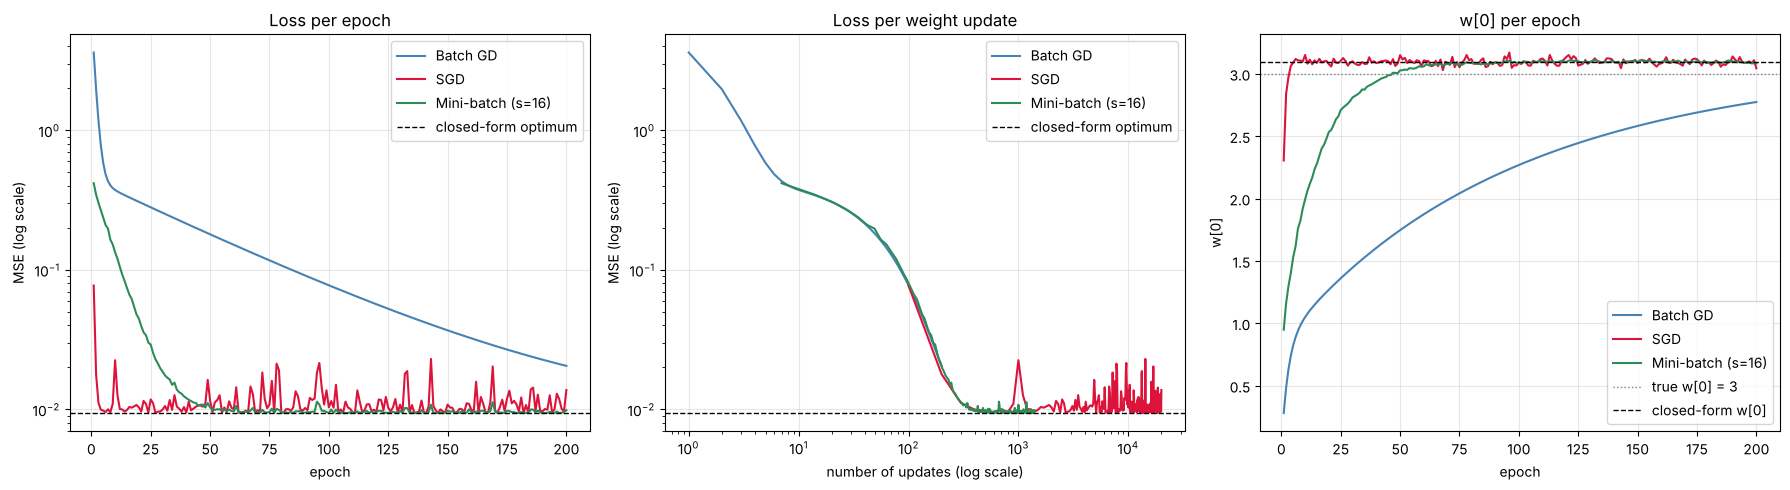

In [9]:
colors = {"Batch GD": "steelblue", "SGD": "crimson", f"Mini-batch (s={batch_size})": "seagreen"}
epoch_axis = np.arange(1, epochs + 1)

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5))

# 1) loss per epoch
for name, (_, _, loss_, _, upe) in results.items():
    ax1.plot(epoch_axis, loss_, color=colors[name], label=name)
ax1.axhline(loss_star, color="black", ls="--", lw=1, label="closed-form optimum")
ax1.set_yscale("log")
ax1.set_title("Loss per epoch")
ax1.set_xlabel("epoch")
ax1.set_ylabel("MSE (log scale)")
ax1.legend()
ax1.grid(alpha=0.3)

# 2) loss per update (same data, x-axis counts weight updates instead of epochs)
for name, (_, _, loss_, _, upe) in results.items():
    ax2.plot(epoch_axis * upe, loss_, color=colors[name], label=name)
ax2.axhline(loss_star, color="black", ls="--", lw=1, label="closed-form optimum")
ax2.set_xscale("log")
ax2.set_yscale("log")
ax2.set_title("Loss per weight update")
ax2.set_xlabel("number of updates (log scale)")
ax2.set_ylabel("MSE (log scale)")
ax2.legend()
ax2.grid(alpha=0.3)

# 3) w[0] per epoch
for name, (_, _, _, w0_, _) in results.items():
    ax3.plot(epoch_axis, w0_, color=colors[name], label=name)
ax3.axhline(3, color="gray", ls=":", lw=1, label="true w[0] = 3")
ax3.axhline(w_star[0], color="black", ls="--", lw=1, label="closed-form w[0]")
ax3.set_title("w[0] per epoch")
ax3.set_xlabel("epoch")
ax3.set_ylabel("w[0]")
ax3.legend()
ax3.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [10]:
# How many epochs / updates does each method need to get the loss under a threshold?
threshold = 0.0105                      # the noise floor is about 0.0094
batch_long = batch_gd(1000, learning_rate)[2]   # batch GD needs more than 200 epochs

curves = {
    "Batch GD": (batch_long, 1),
    "SGD": (s_loss, m),
    f"Mini-batch (s={batch_size})": (m_loss, int(np.ceil(m / batch_size))),
}
print(f"First epoch with MSE < {threshold}")
for name, (loss_, upe) in curves.items():
    hit = int(np.argmax(loss_ < threshold))
    if loss_[hit] < threshold:
        print(f"  {name:<20} epoch {hit + 1:>4}   ({(hit + 1) * upe} updates)")
    else:
        print(f"  {name:<20} not reached")

First epoch with MSE < 0.0105
  Batch GD             epoch  329   (329 updates)
  SGD                  epoch    4   (400 updates)
  Mini-batch (s=16)    epoch   48   (336 updates)


**How to read the plots**

- *Per epoch (left):* the ordering is SGD, then mini-batch, then batch GD, and it simply follows the number of updates per epoch ($m$, $\lceil m/s \rceil$, and $1$).
- *Per update (middle):* once the x-axis counts weight updates instead of epochs, the three curves almost lie on top of each other, and the cell above shows they need a similar number of updates to reach the same loss. With the same learning rate, one update makes roughly the same progress whether it uses 1, 16, or 100 samples. SGD looks far better on the left only because it takes $m$ times as many steps per epoch, not because its steps are smarter.
- *Where they differ:* near the optimum. SGD's gradient noise never vanishes, so its curve keeps spiking. Mini-batch bounces much less because averaging $s$ samples shrinks the noise. Batch GD has no noise at all but is slow to finish the last stretch.
- *Final values:* none of them land exactly on the true $(3, 2, 0)$. The closed-form solution does not either, since it fits the noise in this particular sample. The fair target for gradient descent is the closed-form row.

## 7. Complexity

Let $E$ be the number of epochs, $m$ the number of samples, $d$ the number of features, and $s$ the mini-batch size. The loss recorded at the end of each epoch costs $O(md)$ per epoch, which does not change any of the totals below.

| Method | updates per epoch | work per update | total work | parallel depth (unlimited processors) |
|---|---|---|---|---|
| Batch GD | $1$ | $O(md)$ | $O(E\,m\,d)$ | $O(E \log m)$ |
| SGD | $m$ | $O(d)$ | $O(E\,m\,d)$ | $O(E\,m)$ |
| Mini-batch | $\lceil m/s \rceil$ | $O(sd)$ | $O(E\,m\,d)$ | $O\!\left(E \lceil m/s \rceil \log s\right)$ |

Key points:

- **Total work is identical** for all three. The difference is how that work is spread across updates.
- **Vectorization** (NumPy, BLAS, GPUs) reduces the constant factor and exploits parallel hardware, but it does not change the total operation count, so big-O work stays $O(E\,m\,d)$.
- **Parallel depth** is where they differ. Batch GD's sum over samples is a reduction that can be done in $O(\log m)$ steps. SGD's updates form a strict chain (each needs the previous $\theta$), so its depth equals its work.
- **Memory:** batch GD needs the whole dataset to form one gradient. SGD only needs one sample at a time.

## 8. Fixing SGD jitter with learning rate decay

With a fixed $\eta$, SGD never settles. A standard fix is to shrink the learning rate over time, for example with inverse-time decay:

$$
\eta_e = \frac{\eta_0}{1 + k\,e}
$$

where $e$ is the epoch index and $k$ controls how fast it decays. Early on the steps are large (fast progress), and later they are small, so the noise gets damped and the weights settle.

SGD + decay: w = [3.09156019 2.03409055], b = -0.0747, final loss = 0.00949


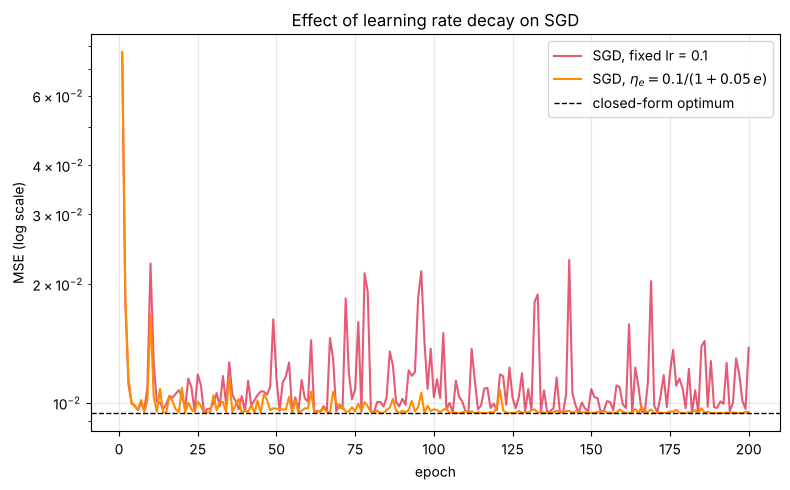

In [11]:
def sgd_decay(epochs, lr0, decay, seed=0):
    shuffle_rng = np.random.default_rng(seed)
    w, b = np.zeros(2), 0.0
    loss_hist = []
    for e in range(epochs):
        lr = lr0 / (1 + decay * e)
        for i in shuffle_rng.permutation(m):
            xi = X[:, i]
            error = np.dot(w, xi) + b - y[i]
            w -= lr * 2 * error * xi
            b -= lr * 2 * error
        loss_hist.append(full_loss(w, b))
    return w, b, np.array(loss_hist)


dw_, db_, d_loss = sgd_decay(epochs, lr0=0.1, decay=0.05)
print(f"SGD + decay: w = {dw_}, b = {db_:.4f}, final loss = {d_loss[-1]:.5f}")

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(epoch_axis, s_loss, color="crimson", alpha=0.7, label="SGD, fixed lr = 0.1")
ax.plot(epoch_axis, d_loss, color="darkorange", label=r"SGD, $\eta_e = 0.1 / (1 + 0.05\,e)$")
ax.axhline(loss_star, color="black", ls="--", lw=1, label="closed-form optimum")
ax.set_yscale("log")
ax.set_title("Effect of learning rate decay on SGD")
ax.set_xlabel("epoch")
ax.set_ylabel("MSE (log scale)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 9. Beyond plain gradient descent: momentum and Adam

The update rule can also be made smarter without changing how the gradient is computed. Here we apply both ideas to the full-batch gradient, with $\theta = (w_1, w_2, b)$ and $g_t = \nabla \mathcal{L}(\theta_{t-1})$.

**Momentum** keeps a running sum of past gradients, so steps build up speed along consistent directions and cancel along oscillating ones:

$$
v_t = \beta\, v_{t-1} + g_t,
\qquad
\theta_t = \theta_{t-1} - \eta\, v_t
$$

**Adam** combines momentum with a per-parameter step size that shrinks for parameters with large gradients:

$$
m_t = \beta_1 m_{t-1} + (1 - \beta_1)\, g_t,
\qquad
v_t = \beta_2 v_{t-1} + (1 - \beta_2)\, g_t^{2}
$$

$$
\hat{m}_t = \frac{m_t}{1 - \beta_1^{\,t}},
\qquad
\hat{v}_t = \frac{v_t}{1 - \beta_2^{\,t}},
\qquad
\theta_t = \theta_{t-1} - \eta\,\frac{\hat{m}_t}{\sqrt{\hat{v}_t} + \epsilon}
$$

The hats are bias corrections, because $m_t$ and $v_t$ start at zero and would otherwise be too small early on. All operations on $g_t^2$ and the square root are element-wise.

Momentum:        w = [3.09535805 2.03600642], b = -0.0691, final loss = 0.00942
Adam (lr = 0.05): w = [2.39927172 1.55273119], b = 0.5496, final loss = 0.05919
Adam (lr = 0.2 ): w = [3.09581007 2.03644257], b = -0.0696, final loss = 0.00942
Adam (lr = 0.5 ): w = [3.09520863 2.0359219 ], b = -0.0690, final loss = 0.00942


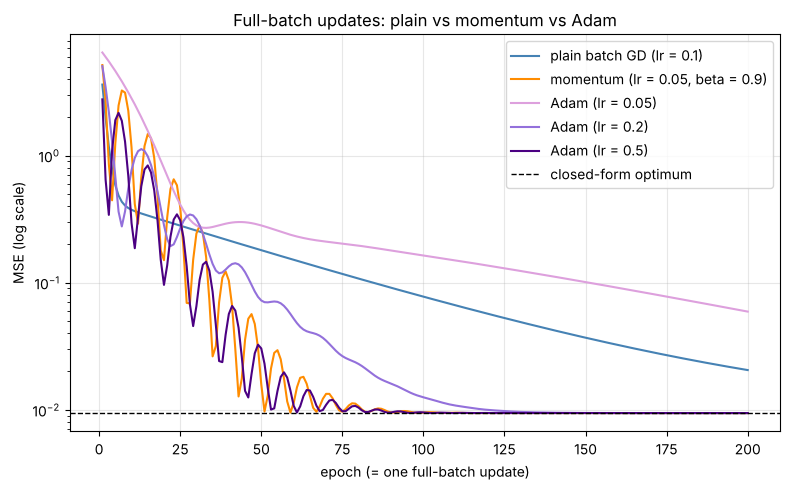

In [12]:
def momentum_gd(epochs, lr, beta=0.9):
    theta, v = np.zeros(3), np.zeros(3)          # theta = [w1, w2, b]
    loss_hist = []
    for _ in range(epochs):
        gw, gb = full_gradient(theta[:2], theta[2])
        g = np.append(gw, gb)
        v = beta * v + g
        theta -= lr * v
        loss_hist.append(full_loss(theta[:2], theta[2]))
    return theta, np.array(loss_hist)


def adam_gd(epochs, lr, beta1=0.9, beta2=0.999, eps=1e-8):
    theta = np.zeros(3)
    m_t, v_t = np.zeros(3), np.zeros(3)
    loss_hist = []
    for t in range(1, epochs + 1):
        gw, gb = full_gradient(theta[:2], theta[2])
        g = np.append(gw, gb)
        m_t = beta1 * m_t + (1 - beta1) * g
        v_t = beta2 * v_t + (1 - beta2) * g ** 2
        m_hat = m_t / (1 - beta1 ** t)
        v_hat = v_t / (1 - beta2 ** t)
        theta -= lr * m_hat / (np.sqrt(v_hat) + eps)
        loss_hist.append(full_loss(theta[:2], theta[2]))
    return theta, np.array(loss_hist)


th_mom, mom_loss = momentum_gd(epochs, lr=0.05, beta=0.9)
adam_runs = {lr: adam_gd(epochs, lr=lr) for lr in (0.05, 0.2, 0.5)}

print(f"Momentum:        w = {th_mom[:2]}, b = {th_mom[2]:.4f}, final loss = {mom_loss[-1]:.5f}")
for lr, (th, loss_) in adam_runs.items():
    print(f"Adam (lr = {lr:<4}): w = {th[:2]}, b = {th[2]:.4f}, final loss = {loss_[-1]:.5f}")

adam_colors = {0.05: "plum", 0.2: "mediumpurple", 0.5: "indigo"}

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(epoch_axis, b_loss, color="steelblue", label="plain batch GD (lr = 0.1)")
ax.plot(epoch_axis, mom_loss, color="darkorange", label="momentum (lr = 0.05, beta = 0.9)")
for lr, (_, loss_) in adam_runs.items():
    ax.plot(epoch_axis, loss_, color=adam_colors[lr], label=f"Adam (lr = {lr})")
ax.axhline(loss_star, color="black", ls="--", lw=1, label="closed-form optimum")
ax.set_yscale("log")
ax.set_title("Full-batch updates: plain vs momentum vs Adam")
ax.set_xlabel("epoch (= one full-batch update)")
ax.set_ylabel("MSE (log scale)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**What the plot shows**

- *Momentum* overshoots and oscillates early (the velocity carries it past the minimum), then converges far faster than plain batch GD, which is still well above the optimum after 200 updates. With $\beta = 0.9$ the effective step is roughly $\eta / (1 - \beta) = 10\eta$, which is why it is both faster and oscillatory.
- *Adam* is sensitive to its learning rate here. Its per-parameter step is roughly $\eta$ in size regardless of the gradient's scale, so a small $\eta$ (0.05) makes it *slower* than plain GD in this run, while larger values reach the optimum. These runs use fixed hyperparameters with no tuning, so treat the plot as an illustration of the update rules, not a ranking of the optimizers. Adam is designed for noisy, high-dimensional problems, and this tiny convex problem is not where it shines.

## 10. Takeaways

| | Batch | SGD | Mini-batch |
|---|---|---|---|
| Samples per update | $m$ | $1$ | $s$ |
| Updates per epoch | $1$ | $m$ | $\lceil m/s \rceil$ |
| Gradient noise | none | high | medium ($\propto 1/s$) |
| Path | smooth | jittery | slightly jittery |
| Memory per step | whole dataset | one sample | one batch |
| Parallelism within an update | high | none | high |
| Typical use | small data, exact optimization | online learning, very large data | default in deep learning ($s$ around 32 to 256) |

- All three minimize the same loss with the same update rule $\theta \leftarrow \theta - \eta\,g$. Only the gradient estimate $g$ changes.
- Total arithmetic per epoch is the same. What differs is how many parameter updates you get for it, and how well the work parallelizes.
- A fixed learning rate makes the stochastic variants hover near the optimum instead of landing on it. Decay the learning rate (section 8) or increase the batch size to reduce the jitter.
- For plain linear regression you never *need* gradient descent, since the closed form (section 5) is exact. It is used here because the same machinery carries over to models that have no closed form, such as neural networks.